# Municipal Reports | NLP Capstone Project
## بلاغات البلدية
**SDAIA Academy · SDA-AIE-211 · Natural Language Processing with Transformers**

A prototype for routing municipal reports, extracting issue/location information and retrieving similar cases. The original lab dataset contains 12 Arabic reports and five topics. It is a teaching sample, not a representative production dataset. English and dialect support require further labeled data.

**How to run:** Run all cells in Colab. The offline baseline runs without downloading models; set `RUN_TRANSFORMERS = True` and run again for the optional model experiments (internet and preferably GPU required).

## 1. Problem and objectives
### المشكلة والأهداف
Manual routing of municipal complaints is time-consuming. The prototype explores privacy-aware preprocessing, topic classification, contextual representations, entity extraction, semantic retrieval and evaluation. The intended outcome is decision support for municipal staff, not automatic emergency dispatch.

## 2. Setup and dataset
### الإعداد ومجموعة البيانات
The following records are copied from the original Lab 3A notebook. Group identifiers are educational IDs. The data are embedded so no external CSV is needed to run the notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
RUN_TRANSFORMERS = False


,citizen_id,text,topic
0,1,انقطاع المياه عن الحي منذ الصباح الباكر,water
1,1,تسرب مياه تحت الرصيف يحتاج صيانة عاجلة,water
2,2,تعطل الإشارة المرورية عند التقاطع الرئيسي,roads
3,2,وجود حفرة عميقة في منتصف الطريق,roads
4,3,تراكم النفايات قرب الحاويات في الشارع العام,waste
5,3,تأخر رفع المخلفات المنزلية في الحي,waste
6,4,تلف إنارة الممر والمشاة ليلاً,lighting
7,4,أعمدة الإنارة مطفأة في الشارع الفرعي,lighting
8,5,لا أستطيع تقديم البلاغ عبر الخدمة الإلكترونية,digital_services
9,5,التطبيق البلدي يغلق عند إرفاق الصور,digital_services


Reports: 12 Groups: 6


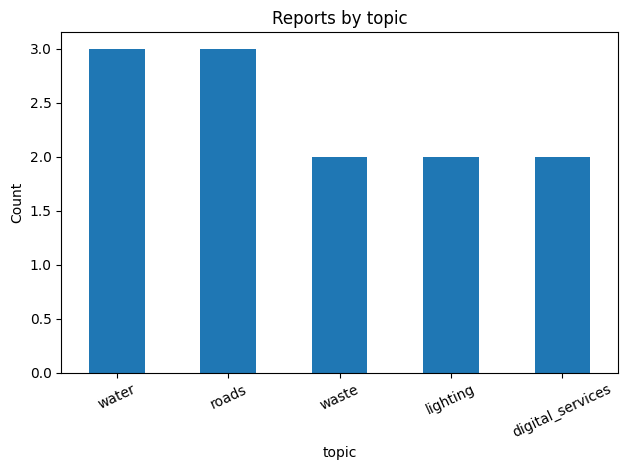

In [2]:
import pandas as pd

data = {
    "citizen_id": [1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6],
    "text": [
        "انقطاع المياه عن الحي منذ الصباح الباكر",
        "تسرب مياه تحت الرصيف يحتاج صيانة عاجلة",
        "تعطل الإشارة المرورية عند التقاطع الرئيسي",
        "وجود حفرة عميقة في منتصف الطريق",
        "تراكم النفايات قرب الحاويات في الشارع العام",
        "تأخر رفع المخلفات المنزلية في الحي",
        "تلف إنارة الممر والمشاة ليلاً",
        "أعمدة الإنارة مطفأة في الشارع الفرعي",
        "لا أستطيع تقديم البلاغ عبر الخدمة الإلكترونية",
        "التطبيق البلدي يغلق عند إرفاق الصور",
        "تضرر الأسفلت بعد هطول الأمطار",
        "مشكلة في ضغط شبكة المياه بالمنطقة"
    ],
    "topic": [
        "water",
        "water",
        "roads",
        "roads",
        "waste",
        "waste",
        "lighting",
        "lighting",
        "digital_services",
        "digital_services",
        "roads",
        "water"
    ]
}


df = pd.DataFrame(data)
labels = sorted(df.topic.unique())
display(df)
print("Reports:", len(df), "Groups:", df.citizen_id.nunique())
df.topic.value_counts().plot.bar(title="Reports by topic", ylabel="Count", rot=25);
plt.tight_layout(); plt.show()

## 3. Text preprocessing and privacy
### معالجة النصوص والخصوصية
Normalize Unicode and whitespace, remove decorative elongation, and mask common phone, ID and email patterns. Preserve sentiment-bearing punctuation and emoji. Regex masking is not complete PII detection; names and addresses require additional controls.

In [3]:
import re
import unicodedata
VERSION = '1.0.0'

def preprocess(text):
    text = unicodedata.normalize('NFC', str(text))
    text = re.sub(r'[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}', '[EMAIL]', text)
    text = re.sub(r'(?<!\d)(?:\+?966|0)5\d{8}(?!\d)', '[PHONE]', text)
    text = re.sub(r'(?<!\d)[12]\d{9}(?!\d)', '[ID]', text)
    return re.sub(r'\s+', ' ', text.replace('ـ', '')).strip()

assert preprocess("اتصل 0501234567") == "اتصل [PHONE]"
assert preprocess("البريد a@example.com") == "البريد [EMAIL]"
assert preprocess("هــذا   بلاغ") == "هذا بلاغ"
df["clean_text"] = df.text.map(preprocess)
print("3 preprocessing checks passed")

3 preprocessing checks passed


## 4. Classification baseline and leakage-aware evaluation
### التصنيف والتقييم دون تسرب البيانات
Use a character TF-IDF baseline and logistic regression. Hold out entire citizen groups, as in Lab 3A. Because some topics occur in only one group, this split may omit classes from training; report this explicitly rather than claiming reliable accuracy.

Train/test: 8 4
Unseen training classes: ['water']
                  precision    recall  f1-score   support

digital_services       0.00      0.00      0.00         0
        lighting       0.00      0.00      0.00         0
           roads       1.00      1.00      1.00         1
           waste       0.00      0.00      0.00         0
           water       0.00      0.00      0.00         3

        accuracy                           0.25         4
       macro avg       0.20      0.20      0.20         4
    weighted avg       0.25      0.25      0.25         4



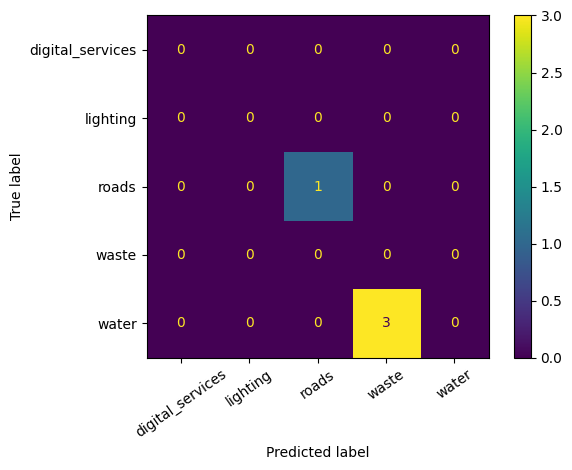

,text,topic,prediction
0,انقطاع المياه عن الحي منذ الصباح الباكر,water,waste
1,تسرب مياه تحت الرصيف يحتاج صيانة عاجلة,water,waste
10,تضرر الأسفلت بعد هطول الأمطار,roads,roads
11,مشكلة في ضغط شبكة المياه بالمنطقة,water,waste


In [4]:
split = GroupShuffleSplit(n_splits=1,test_size=.25,random_state=101)
a,b = next(split.split(df,groups=df.citizen_id))
train,test = df.iloc[a],df.iloc[b]
assert not set(train.citizen_id)&set(test.citizen_id)
print("Train/test:",len(train),len(test))
print("Unseen training classes:", sorted(set(labels)-set(train.topic)))
baseline = make_pipeline(TfidfVectorizer(analyzer="char",ngram_range=(2,4)),LogisticRegression(max_iter=1000))
baseline.fit(train.clean_text,train.topic)
pred = baseline.predict(test.clean_text)
print(classification_report(test.topic,pred,labels=labels,zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(test.topic,pred,labels=labels),display_labels=labels).plot(xticks_rotation=35); plt.tight_layout(); plt.show()
display(test[["text","topic"]].assign(prediction=pred))

## 5. Transformer architecture and tokenization
### بنية المحولات والتقطيع
Encoders such as CAMeLBERT use bidirectional self-attention to contextualize subword tokens. WordPiece and SentencePiece are alternative segmentation methods. Fertility = subword pieces / whitespace words. Compare tokenizer coverage and unknown tokens on the same corpus. The following small NumPy attention example illustrates scaled dot-product attention; its matrices are synthetic, not learned model explanations.

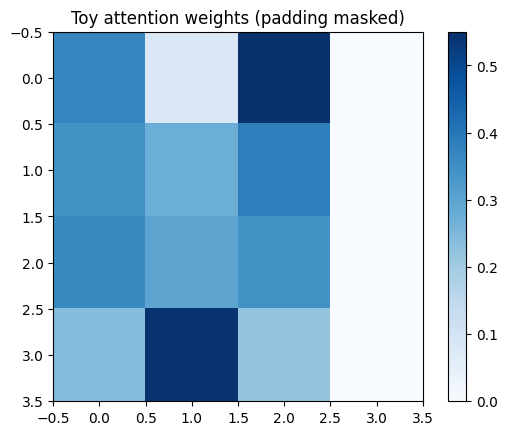

In [5]:
rng=np.random.default_rng(42)
q,k,v=[rng.normal(size=(4,8)) for _ in range(3)]
scores=q@k.T/np.sqrt(k.shape[-1])
scores[:, -1]=-np.inf # mask one padding key before softmax
w=np.exp(scores-scores.max(axis=1,keepdims=True)); w/=w.sum(axis=1,keepdims=True)
assert np.allclose(w.sum(axis=1),1) and np.allclose(w[:,-1],0)
context=w@v
plt.imshow(w,cmap="Blues"); plt.colorbar(); plt.title("Toy attention weights (padding masked)"); plt.show()

## 6. Optional transformer experiments
### تجارب المحولات والتدريب المخصص
These cells download pretrained checkpoints and train a new CAMeLBERT classifier when enabled. They are not executed in the distributed notebook. Multi-head attention combines separate learned projections; the tokenizer must match the checkpoint. The group split remains too small for meaningful model comparison.

In [6]:
if RUN_TRANSFORMERS:
    import sys, subprocess
    subprocess.check_call([sys.executable,"-m","pip","install","-q","transformers>=4.48,<5","datasets","accelerate","sentence-transformers","faiss-cpu"])
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding
    from datasets import Dataset
    checkpoint="CAMeL-Lab/bert-base-arabic-camelbert-mix"
    for name in [checkpoint,"bert-base-multilingual-cased","xlm-roberta-base"]:
        tok=AutoTokenizer.from_pretrained(name)
        pieces=[tok.tokenize(t) for t in df.clean_text]
        print(name, "fertility",sum(map(len,pieces))/sum(len(t.split()) for t in df.clean_text),"unknown pieces",sum(x.count(tok.unk_token) for x in pieces))
    tokenizer=AutoTokenizer.from_pretrained(checkpoint)
    mapping={l:i for i,l in enumerate(labels)}
    def encode(frame):
        d=Dataset.from_dict({"text":frame.clean_text.tolist(),"labels":frame.topic.map(mapping).tolist()})
        return d.map(lambda batch:tokenizer(batch["text"],truncation=True,max_length=128),batched=True,remove_columns=["text"])
    model=AutoModelForSequenceClassification.from_pretrained(checkpoint,num_labels=len(labels),id2label=dict(enumerate(labels)),label2id=mapping)
    print("Parameters:",sum(p.numel() for p in model.parameters()))
    trainer=Trainer(model=model,args=TrainingArguments(output_dir="municipal_model",num_train_epochs=5,per_device_train_batch_size=4,learning_rate=3e-5,report_to="none",seed=101),train_dataset=encode(train),data_collator=DataCollatorWithPadding(tokenizer))
    trainer.train()
    predicted=trainer.predict(encode(test)).predictions.argmax(axis=1)
    print(classification_report(test.topic,[labels[i] for i in predicted],labels=labels,zero_division=0))
else:
    print("Transformer experiment not run; enable RUN_TRANSFORMERS to execute.")

Transformer experiment not run; enable RUN_TRANSFORMERS to execute.


## 7. Arabic NLP and entity extraction
### معالجة العربية واستخراج الكيانات
Saudi dialect variants such as الموية and المياه can express the same issue. This small rule-based extractor demonstrates issue and location fields; it is not trained NER. For a full NER experiment, annotate BIO spans, align subwords, and evaluate exact entity spans using precision, recall and F1.

In [7]:
import re
def extract_entities(text):
    issue=re.search(r"تسرب مياه|انقطاع المياه|الموية مقطوعة|تراكم النفايات|حفرة|تعطل الإشارة|تلف إنارة",text)
    loc=re.search(r"(?:حي|شارع)\s+[\w]+",text)
    return {"issue":issue.group() if issue else None,"location":loc.group() if loc else None}
print(extract_entities("تسرب مياه في حي السعادة"))

{'issue': 'تسرب مياه', 'location': 'حي السعادة'}


## 8. Semantic search and retrieval
### البحث الدلالي واسترجاع البلاغات
The original Lab 5 used multilingual MiniLM and FAISS. Here the optional transformer branch uses normalized embeddings and inner product (cosine similarity), followed by a cross-encoder reranker. The default offline branch is explicitly lexical, not semantic. Retrieval evaluation uses three separately written queries with manually assigned relevant document indices; it is a demonstration, not a benchmark.

In [8]:
from sklearn.metrics.pairwise import cosine_similarity
queries=[("الموية مقطوعة",{0}), ("حفرة في الطريق",{3}), ("النفايات قرب الحاويات",{4})]
if RUN_TRANSFORMERS:
    import faiss
    from sentence_transformers import SentenceTransformer, CrossEncoder
    embedder=SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
    vectors=embedder.encode(df.clean_text.tolist(),normalize_embeddings=True).astype("float32")
    index=faiss.IndexFlatIP(vectors.shape[1]); index.add(vectors)
    reranker=CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")
    def search(query,k=3):
        _,ids=index.search(embedder.encode([preprocess(query)],normalize_embeddings=True).astype("float32"),min(k,len(df)))
        ids=ids[0]; scores=reranker.predict([(query,df.clean_text.iloc[i]) for i in ids]); return ids[np.argsort(-scores)]
else:
    vec=TfidfVectorizer(analyzer="char",ngram_range=(2,4)); matrix=vec.fit_transform(df.clean_text)
    def search(query,k=3):
        scores=cosine_similarity(vec.transform([preprocess(query)]),matrix)[0]; return np.argsort(-scores,kind="stable")[:k]
rr=[]; recalls=[]
for query,relevant in queries:
    ids=search(query); rank=next((j for j,i in enumerate(ids,1) if i in relevant),None)
    rr.append(1/rank if rank else 0); recalls.append(len(set(ids)&relevant)/len(relevant))
    print(query, "→",df.text.iloc[ids[0]])
print("MRR@3:",np.mean(rr),"Recall@3:",np.mean(recalls))

الموية مقطوعة → تأخر رفع المخلفات المنزلية في الحي
حفرة في الطريق → وجود حفرة عميقة في منتصف الطريق
النفايات قرب الحاويات → تراكم النفايات قرب الحاويات في الشارع العام
MRR@3: 0.7777777777777777 Recall@3: 1.0


## 9. Integrated demonstration
### العرض التجريبي المتكامل
The default pipeline combines the fitted baseline with the rule-based entity extractor and retrieval. The classification is experimental and should be reviewed by staff. The optional transformer experiment is separate from this default classifier.

In [9]:
def analyze_report(text):
    clean=preprocess(text)
    return {"clean_text":clean,"suggested_topic":baseline.predict([clean])[0],"entities":extract_entities(clean),"similar_reports":df.text.iloc[search(clean)].tolist()}
display(analyze_report("تسرب مياه في حي السعادة"))

{'clean_text': 'تسرب مياه في حي السعادة',
 'suggested_topic': 'waste',
 'entities': {'issue': 'تسرب مياه', 'location': 'حي السعادة'},
 'similar_reports': ['تسرب مياه تحت الرصيف يحتاج صيانة عاجلة',
  'انقطاع المياه عن الحي منذ الصباح الباكر',
  'مشكلة في ضغط شبكة المياه بالمنطقة']}

## 10. Inference optimization and deployment
### تحسين الاستدلال والنشر
Measure local prototype latency. This is not transformer latency. Future work: dynamic padding, ONNX export, INT8 quantization, p50/p95 latency and memory measurement before/after optimization, and accuracy regression checks. Deploy via a reviewed API or dashboard only after privacy and quality validation.

In [10]:
import time
latencies=[]
for _ in range(20):
    start=time.perf_counter(); analyze_report("حفرة في الطريق"); latencies.append((time.perf_counter()-start)*1000)
print("Local integrated prototype p50/p95 (ms):",np.percentile(latencies,[50,95]).round(2))

Local integrated prototype p50/p95 (ms): [0.94 1.18]


## 11. Limitations and future work
### القيود والتطوير المستقبلي
- Only 12 Arabic topic examples and six groups; no reliable generalization claims.
- Collect consented, de-identified, bilingual and dialect-labeled data; ensure every class has multiple independent groups.
- Train and evaluate NER, sentiment classification and extractive question answering with appropriate labeled datasets.
- Report macro-F1, per-language and dialect slices, span-level NER F1, retrieval Recall@k/MRR and latency on representative samples.
- Original Lab 4 scores and Lab 6 illustrative predictions are not measured model performance.
- Complete production optimization and human review safeguards.

## 12. Conclusion
### الخاتمة
This capstone connects the original municipal-report labs into a reproducible educational prototype. The default pipeline demonstrates the workflow; optional transformer cells extend it toward the course objectives. The accompanying slides and original labs provide further context.